# Figure S3 — movement speed and ensemble activity

This plot-only notebook reads the compact Figure S3 source tables, recreates panel A, and performs the paired mouse-level analyses used for panels B and C. It does not read raw recordings or redefine preprocessing functions.

**Cohort and caption provenance warning.** The accepted plots explicitly exclude `NC326_WT`, leaving 10 WT mice in the OFT paired comparisons. Those plotted data contain **193 center-ON and 220 corner-ON neurons**. The final manuscript caption instead reports **203 center-ON and 226 corner-ON neurons** while also saying that 10 WT mice were used. Those caption counts correspond to the earlier 11-WT table. This notebook preserves the accepted 10-WT plotting cohort and reports the counts actually analyzed; it does not silently force the data to agree with the conflicting caption.

Within each temporal analysis, the six paired Wilcoxon tests (three assays × two genotypes) are corrected together using Benjamini–Hochberg FDR.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

plt.rcParams.update({
    'font.size': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'pyproject.toml').is_file()
)
SOURCE = ROOT / 'data' / 'source_data' / 'figure_s03'
FIGURES = ROOT / 'results' / 'figures'
TABLES = ROOT / 'results' / 'tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

WT_PLOT_COHORT = [
    'NC139_WT', 'NC158_WT', 'NC228_WT', 'NC297_WT', 'NC298_WT',
    'NC308_WT', 'NC314_WT', 'NC315_WT', 'NC324_WT', 'NC463_WT',
]
RTT_PLOT_COHORT = [
    'NC114_RTT', 'NC149_RTT', 'NC159_RTT', 'NC227_RTT', 'NC232_RTT',
    'NC296_RTT', 'NC303_RTT', 'NC304_RTT', 'NC313_RTT',
    'NC464_RTT', 'NC468_RTT',
]
SELECTED_MICE = set(WT_PLOT_COHORT + RTT_PLOT_COHORT)

print('Repository root located from pyproject.toml.')
print(f'Accepted plot cohort: {len(WT_PLOT_COHORT)} WT and {len(RTT_PLOT_COHORT)} RTT mice')

Repository root located from pyproject.toml.
Accepted plot cohort: 10 WT and 11 RTT mice


## S3A — ensemble transient rate versus movement speed

Each point is one 10-s interval. The two panels use the same 178 intervals pooled from 16 mice, as described in the final caption.

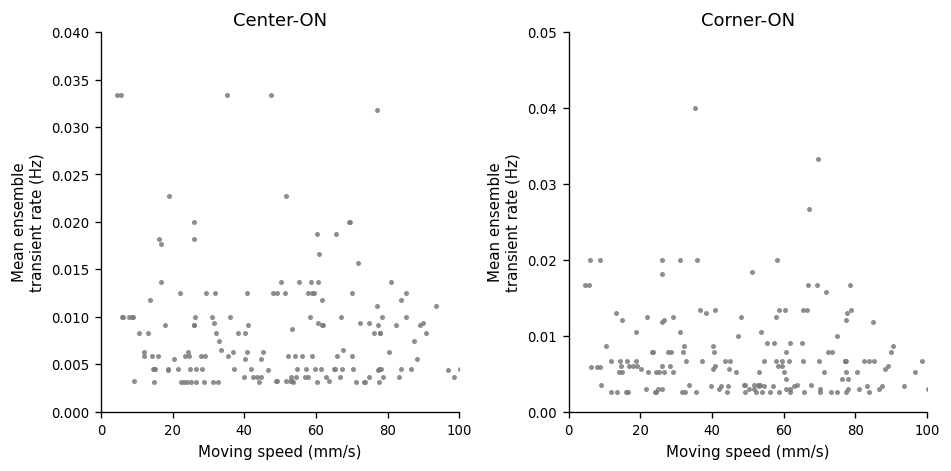

S3A: 178 intervals from 16 mice.


In [2]:
s3a = pd.read_csv(SOURCE / 's3a_transient_rate_vs_speed.csv', keep_default_na=False)
s3a = s3a.loc[:, ~s3a.columns.astype(str).str.startswith('Unnamed:')]
for column in ['speed', 'CenterON_ER', 'CornerON_ER']:
    s3a[column] = pd.to_numeric(s3a[column], errors='coerce')
s3a = s3a.dropna(subset=['speed', 'CenterON_ER', 'CornerON_ER']).copy()

assert len(s3a) == 178, f'Expected 178 plotted intervals, found {len(s3a)}.'
assert s3a['mouse'].nunique() == 16, f"Expected 16 mice, found {s3a['mouse'].nunique()}."

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
panel_specs = [
    ('CenterON_ER', 'Center-ON', (0, 0.04)),
    ('CornerON_ER', 'Corner-ON', (0, 0.05)),
]
for ax, (rate_column, title, ylim) in zip(axes, panel_specs):
    ax.scatter(s3a['speed'], s3a[rate_column], s=9, color='0.48', alpha=0.85, linewidth=0)
    ax.set_title(title, pad=4)
    ax.set_xlabel('Moving speed (mm/s)')
    ax.set_ylabel('Mean ensemble\ntransient rate (Hz)')
    ax.set_xlim(0, 100)
    ax.set_ylim(*ylim)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.tick_params(labelsize=8)
fig.tight_layout()
fig.savefig(FIGURES / 'fig_s3a_speed_vs_transient_rate.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print(f"S3A: {len(s3a)} intervals from {s3a['mouse'].nunique()} mice.")

## S3B/S3C — paired mouse-level neuron–speed correlations

Neuron-level Pearson correlations are averaged within each mouse and OF-defined ensemble. Only mice containing both center-ON and corner-ON values in a given assay are retained for that paired comparison. Social/mTC neurons repeated across sessions are counted once when reporting unique neuron counts.

In [3]:
source_files = {
    ('instantaneous', 'OFT'): 'oft_instantaneous.csv',
    ('instantaneous', 'EPM'): 'epm_instantaneous.csv',
    ('instantaneous', 'mTC'): 'mtc_instantaneous.csv',
    ('2s', 'OFT'): 'oft_2s.csv',
    ('2s', 'EPM'): 'epm_2s.csv',
    ('2s', 'mTC'): 'mtc_2s.csv',
}

correlation_tables = {}
for key, filename in source_files.items():
    table = pd.read_csv(SOURCE / filename, keep_default_na=False)
    table = table.loc[:, ~table.columns.astype(str).str.startswith('Unnamed:')]
    table['pearson_r'] = pd.to_numeric(table['pearson_r'], errors='coerce')
    table = table[table['mouse'].isin(SELECTED_MICE)].dropna(
        subset=['mouse', 'neuron', 'neuornType', 'pearson_r']
    ).copy()
    table['genotype'] = np.where(table['mouse'].isin(WT_PLOT_COHORT), 'WT', 'RTT')
    correlation_tables[key] = table

caption_counts = {
    ('instantaneous', 'OFT', 'WT'): (203, 226),
    ('instantaneous', 'OFT', 'RTT'): (77, 103),
    ('instantaneous', 'EPM', 'WT'): (86, 88),
    ('instantaneous', 'EPM', 'RTT'): (20, 35),
    ('instantaneous', 'mTC', 'WT'): (64, 59),
    ('instantaneous', 'mTC', 'RTT'): (33, 43),
    ('2s', 'OFT', 'WT'): (203, 226),
    ('2s', 'OFT', 'RTT'): (77, 103),
    ('2s', 'EPM', 'WT'): (99, 111),
    ('2s', 'EPM', 'RTT'): (20, 35),
    ('2s', 'mTC', 'WT'): (64, 59),
    ('2s', 'mTC', 'RTT'): (33, 43),
}

paired_tables = {}
statistics_rows = []
paired_rows = []
for analysis in ['instantaneous', '2s']:
    for assay in ['OFT', 'EPM', 'mTC']:
        table = correlation_tables[(analysis, assay)]
        for genotype in ['WT', 'RTT']:
            group = table[table['genotype'].eq(genotype)].copy()
            mouse_means = group.groupby(['mouse', 'neuornType'])['pearson_r'].mean().unstack('neuornType')
            paired = mouse_means.reindex(columns=['ceON', 'coON']).dropna().sort_index()
            if paired.empty:
                raise ValueError(f'No paired mice for {analysis}, {assay}, {genotype}.')
            paired_tables[(analysis, assay, genotype)] = paired
            wilcoxon_w, raw_p = wilcoxon(
                paired['ceON'], paired['coON'], alternative='two-sided', method='auto'
            )
            paired_neurons = group[group['mouse'].isin(paired.index)]
            center_count = paired_neurons.loc[
                paired_neurons['neuornType'].eq('ceON'), ['mouse', 'neuron']
            ].drop_duplicates().shape[0]
            corner_count = paired_neurons.loc[
                paired_neurons['neuornType'].eq('coON'), ['mouse', 'neuron']
            ].drop_duplicates().shape[0]
            caption_center, caption_corner = caption_counts[(analysis, assay, genotype)]
            statistics_rows.append({
                'analysis': analysis,
                'assay': assay,
                'genotype': genotype,
                'paired_mice': len(paired),
                'paired_mouse_ids': ';'.join(paired.index),
                'centerON_unique_neurons': center_count,
                'cornerON_unique_neurons': corner_count,
                'centerON_mean_r': paired['ceON'].mean(),
                'cornerON_mean_r': paired['coON'].mean(),
                'mean_paired_difference_center_minus_corner': (paired['ceON'] - paired['coON']).mean(),
                'wilcoxon_W': wilcoxon_w,
                'p_value': raw_p,
                'caption_centerON_unique_neurons': caption_center,
                'caption_cornerON_unique_neurons': caption_corner,
                'caption_count_matches_plot_cohort': (
                    center_count == caption_center and corner_count == caption_corner
                ),
            })
            for mouse, values in paired.iterrows():
                paired_rows.append({
                    'analysis': analysis, 'assay': assay, 'genotype': genotype,
                    'mouse': mouse, 'centerON_mean_r': values['ceON'],
                    'cornerON_mean_r': values['coON'],
                })

statistics = pd.DataFrame(statistics_rows)
statistics['p_value_fdr_bh'] = np.nan
for analysis in ['instantaneous', '2s']:
    index = statistics.index[statistics['analysis'].eq(analysis)]
    statistics.loc[index, 'p_value_fdr_bh'] = multipletests(
        statistics.loc[index, 'p_value'].to_numpy(), method='fdr_bh'
    )[1]
statistics['significant_fdr_0.05'] = statistics['p_value_fdr_bh'] < 0.05
paired_mouse_means = pd.DataFrame(paired_rows)

statistics.to_csv(TABLES / 'fig_s3_paired_wilcoxon_statistics.csv', index=False)
paired_mouse_means.to_csv(TABLES / 'fig_s3_paired_mouse_means.csv', index=False)
statistics.loc[statistics['analysis'].eq('instantaneous')].to_csv(
    TABLES / 'fig_s3b_instantaneous_statistics.csv', index=False
)
statistics.loc[statistics['analysis'].eq('2s')].to_csv(
    TABLES / 'fig_s3c_two_second_statistics.csv', index=False
)

display(statistics)

,analysis,assay,genotype,paired_mice,paired_mouse_ids,centerON_unique_neurons,cornerON_unique_neurons,centerON_mean_r,cornerON_mean_r,mean_paired_difference_center_minus_corner,wilcoxon_W,p_value,caption_centerON_unique_neurons,caption_cornerON_unique_neurons,caption_count_matches_plot_cohort,p_value_fdr_bh,significant_fdr_0.05
0,instantaneous,OFT,WT,10,NC139_WT;NC158_WT;NC228_WT;NC297_WT;NC298_WT;N...,193,220,0.014057,-0.016325,0.030382,1.0,0.003906,203,226,False,0.023438,True
1,instantaneous,OFT,RTT,7,NC227_RTT;NC232_RTT;NC296_RTT;NC303_RTT;NC...,77,103,0.026928,-0.012017,0.038944,0.0,0.015625,77,103,True,0.046875,True
2,instantaneous,EPM,WT,8,NC139_WT;NC158_WT;NC228_WT;NC297_WT;NC298_WT;N...,86,88,0.010618,0.002977,0.007640,14.0,0.640625,86,88,True,0.812500,False
3,instantaneous,EPM,RTT,5,NC227_RTT;NC232_RTT;NC296_RTT;NC303_RTT;NC...,20,35,0.021194,0.011605,0.009589,6.0,0.812500,20,35,True,0.812500,False
4,instantaneous,mTC,WT,7,NC139_WT;NC158_WT;NC228_WT;NC297_WT;NC298_WT;N...,64,59,-0.006436,-0.003575,-0.002861,11.0,0.687500,64,59,True,0.812500,False
5,instantaneous,mTC,RTT,6,NC227_RTT;NC232_RTT;NC296_RTT;NC303_RTT;NC...,33,43,-0.012501,-0.006933,-0.005567,8.0,0.687500,33,43,True,0.812500,False
6,2s,OFT,WT,10,NC139_WT;NC158_WT;NC228_WT;NC297_WT;NC298_WT;N...,193,220,0.029188,-0.023268,0.052456,1.0,0.003906,203,226,False,0.023438,True
7,2s,OFT,RTT,7,NC227_RTT;NC232_RTT;NC296_RTT;NC303_RTT;NC...,77,103,0.056380,-0.017133,0.073513,0.0,0.015625,77,103,True,0.046875,True
8,2s,EPM,WT,9,NC139_WT;NC158_WT;NC228_WT;NC297_WT;NC298_WT;N...,99,111,0.013879,0.000744,0.013135,19.0,0.734375,99,111,True,0.881250,False
9,2s,EPM,RTT,5,NC227_RTT;NC232_RTT;NC296_RTT;NC303_RTT;NC...,20,35,0.046486,0.018568,0.027918,5.0,0.625000,20,35,True,0.881250,False


### Caption-count check

The table below is intentionally displayed and saved with the statistics. A `False` value is a provenance conflict, not a value to be overwritten. The OFT/WT mismatch is the known 10-WT-versus-11-WT caption issue described above.

In [4]:
caption_count_check_columns = [
    'analysis', 'assay', 'genotype', 'paired_mice',
    'centerON_unique_neurons', 'cornerON_unique_neurons',
    'caption_centerON_unique_neurons', 'caption_cornerON_unique_neurons',
    'caption_count_matches_plot_cohort',
]
caption_count_check = statistics[caption_count_check_columns].copy()
caption_count_check.to_csv(TABLES / 'fig_s3_caption_count_check.csv', index=False)
display(caption_count_check)

conflicts = caption_count_check.loc[~caption_count_check['caption_count_matches_plot_cohort']]
assert len(conflicts) == 2
assert set(conflicts['analysis']) == {'instantaneous', '2s'}
assert set(conflicts['assay']) == {'OFT'}
assert set(conflicts['genotype']) == {'WT'}

,analysis,assay,genotype,paired_mice,centerON_unique_neurons,cornerON_unique_neurons,caption_centerON_unique_neurons,caption_cornerON_unique_neurons,caption_count_matches_plot_cohort
0,instantaneous,OFT,WT,10,193,220,203,226,False
1,instantaneous,OFT,RTT,7,77,103,77,103,True
2,instantaneous,EPM,WT,8,86,88,86,88,True
3,instantaneous,EPM,RTT,5,20,35,20,35,True
4,instantaneous,mTC,WT,7,64,59,64,59,True
5,instantaneous,mTC,RTT,6,33,43,33,43,True
6,2s,OFT,WT,10,193,220,203,226,False
7,2s,OFT,RTT,7,77,103,77,103,True
8,2s,EPM,WT,9,99,111,99,111,True
9,2s,EPM,RTT,5,20,35,20,35,True


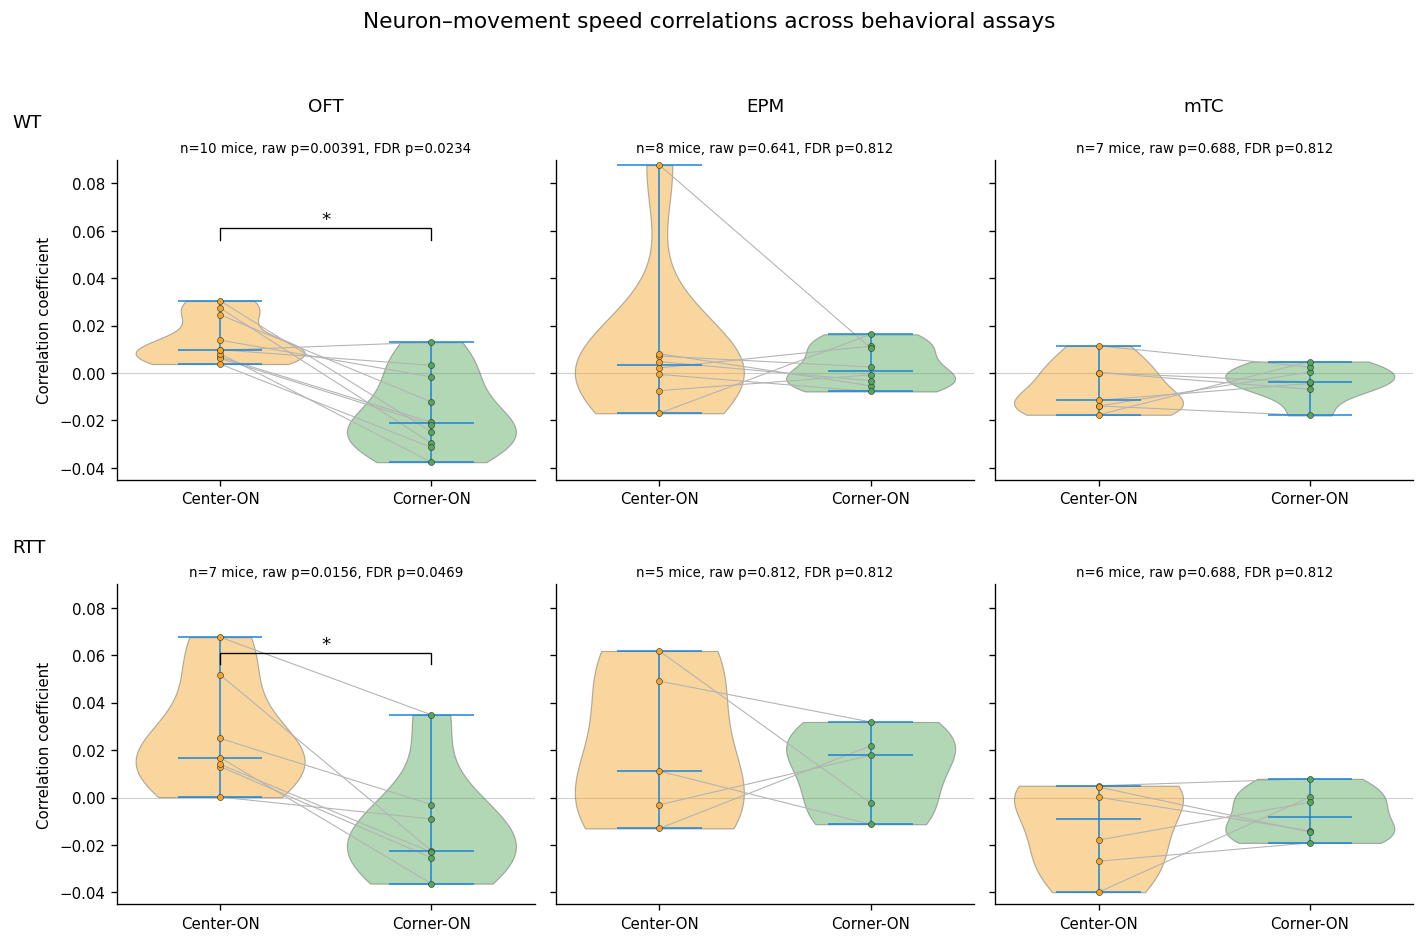

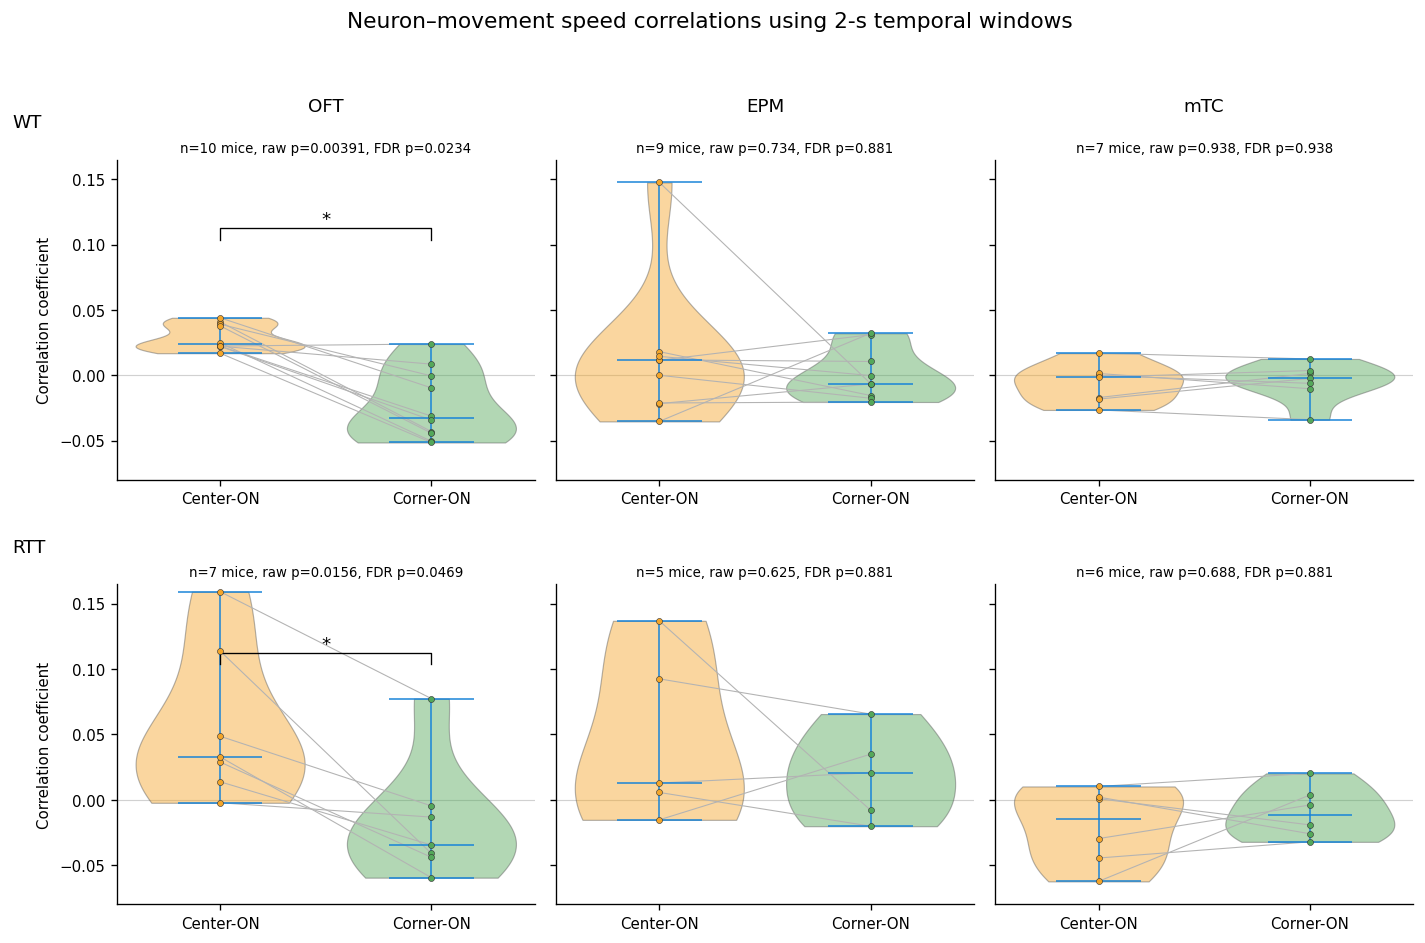

In [5]:
ensemble_colors = {'ceON': '#F4A62A', 'coON': '#54A85A'}
analysis_titles = {
    'instantaneous': 'Neuron–movement speed correlations across behavioral assays',
    '2s': 'Neuron–movement speed correlations using 2-s temporal windows',
}
analysis_outputs = {
    'instantaneous': 'fig_s3b_instantaneous_correlations',
    '2s': 'fig_s3c_two_second_correlations',
}
analysis_ylims = {
    'instantaneous': (-0.045, 0.09),
    '2s': (-0.08, 0.165),
}

for analysis in ['instantaneous', '2s']:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True)
    for column_index, assay in enumerate(['OFT', 'EPM', 'mTC']):
        for row_index, genotype in enumerate(['WT', 'RTT']):
            ax = axes[row_index, column_index]
            paired = paired_tables[(analysis, assay, genotype)]
            center_values = paired['ceON'].to_numpy()
            corner_values = paired['coON'].to_numpy()
            parts = ax.violinplot(
                [center_values, corner_values], positions=[1, 2], widths=0.8,
                showmeans=False, showmedians=True, showextrema=True,
            )
            for body, color in zip(parts['bodies'], [ensemble_colors['ceON'], ensemble_colors['coON']]):
                body.set_facecolor(color)
                body.set_edgecolor('0.35')
                body.set_linewidth(0.7)
                body.set_alpha(0.45)
            for key in ['cbars', 'cmins', 'cmaxes', 'cmedians']:
                parts[key].set_color('#1683D8')
                parts[key].set_linewidth(0.9)
            for center_r, corner_r in zip(center_values, corner_values):
                ax.plot([1, 2], [center_r, corner_r], color='0.70', linewidth=0.65, zorder=1)
            ax.scatter(
                np.ones(len(center_values)), center_values, s=13,
                color=ensemble_colors['ceON'], edgecolor='0.20', linewidth=0.35, zorder=3,
            )
            ax.scatter(
                np.full(len(corner_values), 2), corner_values, s=13,
                color=ensemble_colors['coON'], edgecolor='0.20', linewidth=0.35, zorder=3,
            )
            result = statistics.loc[
                statistics['analysis'].eq(analysis)
                & statistics['assay'].eq(assay)
                & statistics['genotype'].eq(genotype)
            ].iloc[0]
            ax.set_ylim(*analysis_ylims[analysis])
            ax.axhline(0, color='0.82', linewidth=0.7, zorder=0)
            ax.set_xticks([1, 2], ['Center-ON', 'Corner-ON'])
            ax.text(
                0.5, 1.015,
                f"n={int(result['paired_mice'])} mice, raw p={result['p_value']:.3g}, "
                f"FDR p={result['p_value_fdr_bh']:.3g}",
                transform=ax.transAxes, ha='center', va='bottom', fontsize=8,
            )
            if row_index == 0:
                ax.set_title(assay, fontsize=11, pad=29)
            if column_index == 0:
                ax.set_ylabel('Correlation coefficient')
                ax.text(-0.25, 1.10, genotype, transform=ax.transAxes, fontsize=11, ha='left')
            if bool(result['significant_fdr_0.05']):
                y_min, y_max = analysis_ylims[analysis]
                bracket_y = y_max - 0.25 * (y_max - y_min)
                bracket_h = 0.035 * (y_max - y_min)
                ax.plot(
                    [1, 1, 2, 2],
                    [bracket_y, bracket_y + bracket_h, bracket_y + bracket_h, bracket_y],
                    color='black', linewidth=0.8,
                )
                ax.text(1.5, bracket_y + bracket_h, '*', ha='center', va='bottom', fontsize=11)
    fig.suptitle(analysis_titles[analysis], fontsize=13, y=0.995)
    fig.tight_layout(rect=(0.02, 0.02, 1, 0.96), h_pad=2.0, w_pad=1.0)
    output_stem = analysis_outputs[analysis]
    fig.savefig(FIGURES / f'{output_stem}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)